In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

PROJECT_DIR = Path(
    r"C:\Users\Preetham\Downloads\collections_30k_dataset (1)"
)
REPORTS_DIR = PROJECT_DIR / "reports"

golden_file = REPORTS_DIR / "golden_payments_dataset.csv"
golden = pd.read_csv(golden_file)

print("Golden Dataset loaded successfully!")
print("Rows:", len(golden))
print("Columns:", len(golden.columns))

Golden Dataset loaded successfully!
Rows: 25014
Columns: 20


In [2]:

# Data quality checks

print("=== DATASET OVERVIEW ===")
print(f"Rows: {len(golden):,}")
print(f"Columns: {len(golden.columns)}")

print("\n=== MISSING VALUES ===")
display(
    golden.isna().sum()
    .sort_values(ascending=False)
    .to_frame("missing_count")
)

print("\n=== PAYMENT STATUS ===")
display(
    golden["payment_status"]
    .value_counts()
    .rename_axis("payment_status")
    .to_frame("count")
)

print("\n=== DUPLICATE PAYMENT IDS ===")
print("Rows flagged:", int(golden["payment_id_duplicate"].sum()))
print(
    "Repeated payment IDs:",
    golden.loc[golden["payment_id_duplicate"], "payment_id"].nunique()
)

print("\n=== AMOUNT VALIDATION ===")
print("Minimum amount:", golden["amount"].min())
print("Maximum amount:", golden["amount"].max())
print("Non-positive amounts:", int((golden["amount"] <= 0).sum()))

print("\n=== BORROWER ATTRIBUTION ===")
print(
    "Rows where borrower IDs differ:",
    int((golden["borrower_id_x"] != golden["borrower_id_y"]).sum())
)


=== DATASET OVERVIEW ===
Rows: 25,014
Columns: 20

=== MISSING VALUES ===


,missing_count
borrower_id_y,383
payment_reference,382
payment_id,0
account_id,0
event_at,0
borrower_id_x,0
payment_status,0
amount,0
payment_method,0
provider_id,0



=== PAYMENT STATUS ===


,count
payment_status,
SUCCESS,17545
FAILED,3678
PENDING,2536
REVERSED,1255



=== DUPLICATE PAYMENT IDS ===
Rows flagged: 28
Repeated payment IDs: 14

=== AMOUNT VALIDATION ===
Minimum amount: 103.68
Maximum amount: 149993.55
Non-positive amounts: 0

=== BORROWER ATTRIBUTION ===
Rows where borrower IDs differ: 25013


In [3]:

# Monthly successful payment analysis

golden["event_at"] = pd.to_datetime(golden["event_at"], utc=True)

# Extract month in UTC
golden["month"] = golden["event_at"].dt.strftime("%Y-%m")

successful = golden[golden["payment_status"] == "SUCCESS"].copy()

monthly = (
    successful.groupby("month")
    .agg(
        successful_payment_rows=("payment_id", "size"),
        unique_payment_ids=("payment_id", "nunique"),
        unique_accounts=("account_id", "nunique"),
        gross_success_amount=("amount", "sum")
    )
    .reset_index()
    .sort_values("month")
)

monthly["amount_change_pct"] = (
    monthly["gross_success_amount"].pct_change() * 100
).round(2)

monthly["payment_id_change_pct"] = (
    monthly["unique_payment_ids"].pct_change() * 100
).round(2)

monthly["account_change_pct"] = (
    monthly["unique_accounts"].pct_change() * 100
).round(2)

display(monthly.round(2))


,month,successful_payment_rows,unique_payment_ids,unique_accounts,gross_success_amount,amount_change_pct,payment_id_change_pct,account_change_pct
0,2026-01,2464,2464,2374,1.872291e+08,NaN,NaN,NaN
1,2026-02,2270,2268,2173,1.702796e+08,-9.05,-7.95,-8.47
2,2026-03,2527,2524,2419,1.891903e+08,11.11,11.29,11.32
3,2026-04,2407,2406,2304,1.752289e+08,-7.38,-4.68,-4.75
4,2026-05,2450,2449,2344,1.843355e+08,5.20,1.79,1.74
5,2026-06,2369,2366,2286,1.758534e+08,-4.60,-3.39,-2.47
6,2026-07,2442,2441,2335,1.872478e+08,6.48,3.17,2.14
7,2026-08,616,616,608,4.710970e+07,-74.84,-74.76,-73.96


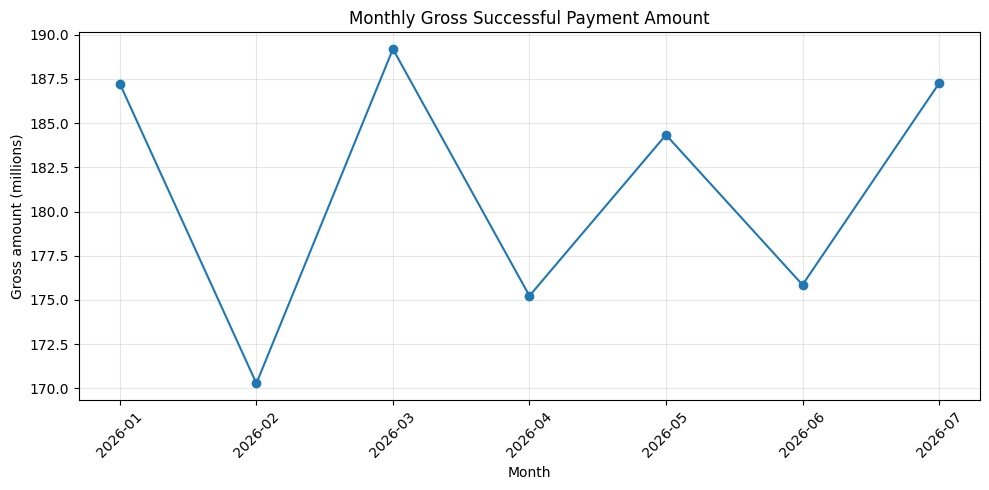

Chart saved to: C:\Users\Preetham\Downloads\collections_30k_dataset (1)\reports\notebook_monthly_recovery_trend.png


In [4]:

# Plot monthly gross successful payment amounts
# Exclude August because it contains only data through August 8.

plot_data = monthly[monthly["month"] != "2026-08"].copy()

plt.figure(figsize=(10, 5))
plt.plot(
    plot_data["month"],
    plot_data["gross_success_amount"] / 1_000_000,
    marker="o"
)

plt.title("Monthly Gross Successful Payment Amount")
plt.xlabel("Month")
plt.ylabel("Gross amount (millions)")
plt.xticks(rotation=45)
plt.grid(True, alpha=0.3)
plt.tight_layout()

chart_path = REPORTS_DIR / "notebook_monthly_recovery_trend.png"
plt.savefig(chart_path, dpi=150, bbox_inches="tight")
plt.show()

print("Chart saved to:", chart_path)


In [5]:

# Final findings and limitations

march_change = monthly.loc[
    monthly["month"] == "2026-03",
    "amount_change_pct"
].iloc[0]

positive_comparisons = int(
    (monthly.loc[monthly["month"] != "2026-01", "amount_change_pct"] > 0).sum()
)

print("RECOVERY ANALYSIS — CONCLUSION")
print("=" * 40)
print(f"March gross successful payment change: {march_change:.2f}%")
print(f"Positive monthly comparisons: {positive_comparisons} of 7")
print()
print("Finding: March recorded an 11.11% increase in gross successful")
print("payment amount, but the increase was not sustained every month.")
print()
print("Limitations:")
print("- Gross successful payment amount is not a recovery rate.")
print("- August is incomplete and should not be compared with full months.")
print("- Reversals and an appropriate eligible-balance denominator must")
print("  be considered before claiming recovery-rate improvement.")
print("- Borrower attribution differences require further investigation.")


RECOVERY ANALYSIS — CONCLUSION
March gross successful payment change: 11.11%
Positive monthly comparisons: 3 of 7

Finding: March recorded an 11.11% increase in gross successful
payment amount, but the increase was not sustained every month.

Limitations:
- Gross successful payment amount is not a recovery rate.
- August is incomplete and should not be compared with full months.
- Reversals and an appropriate eligible-balance denominator must
  be considered before claiming recovery-rate improvement.
- Borrower attribution differences require further investigation.
